# 08 – Evaluation & Comparison

**Project:** Technology & Fintech Market Intelligence and Regime Analyzer  
**Phase:** 4 / 7 – Consolidated evaluation and final comparison report

### Goals
1. Load experiment results from notebooks 05 (ML) and 06 (DL)  
2. Rank all models (baselines + ML + DL) on the held-out test period  
3. Inspect robustness across categories / regimes where data allows  
4. Produce a transparent evaluation report (including cases where complex models lose)  
5. Persist the final comparison artefacts  

### Prerequisites
- Notebooks 05 and/or 06 completed  
- `data/processed/ml_experiment_results.json` and/or `dl_experiment_results.json`  
- Feature panel available for optional robustness checks

In [1]:
# Cell 1 – Imports & setup

from __future__ import annotations

import sys
import json
from pathlib import Path
from typing import Any, Dict, List, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from config import settings
from config.constants import RANDOM_SEED
from src.utils import setup_logging, get_logger, utc_now, ensure_dir, save_json
from src.db.connection import get_client, get_db
from src.db.collections import ensure_indexes
from src.db.analysis_results import save_analysis_result
from src.db.model_evaluations import get_model_evaluations

setup_logging(level="INFO")
logger = get_logger(__name__)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 5)
np.random.seed(RANDOM_SEED)

print("Project root :", PROJECT_ROOT)

Project root : c:\Users\hp\Documents\GitHub\BeneathTheMarket


In [2]:
## 1. Load experiment artefacts

processed_dir = ensure_dir(settings.PROCESSED_DATA_DIR)

def _load_json(path: Path) -> Dict[str, Any]:
    if not path.exists():
        return {}
    with open(path, "r", encoding="utf-8") as f:
        return json.load(f)

ml_doc = _load_json(processed_dir / "ml_experiment_results.json")
dl_doc = _load_json(processed_dir / "dl_experiment_results.json")
feat_meta = _load_json(processed_dir / "feature_metadata.json")
regime_diag = _load_json(processed_dir / "regime_discovery_diagnostics.json")
nlp_summary = _load_json(processed_dir / "nlp_component_summary.json")

print("ML results found :", bool(ml_doc))
print("DL results found :", bool(dl_doc))
print("Feature meta     :", bool(feat_meta))
print("Regime diagnostics:", bool(regime_diag))
print("NLP summary      :", bool(nlp_summary))

HORIZON = feat_meta.get("horizon") or ml_doc.get("horizon") or dl_doc.get("horizon") or 5
print(f"Forecast horizon : {HORIZON} trading days")

ML results found : True
DL results found : True
Feature meta     : True
Regime diagnostics: True
NLP summary      : True
Forecast horizon : 5 trading days


In [3]:
## 2. Build a unified leaderboard

rows = []

# Baselines
for name, m in (ml_doc.get("baselines") or {}).items():
    rows.append({
        "family": "baseline",
        "model": f"baseline_{name}",
        "test_rmse": m.get("rmse"),
        "test_mae": m.get("mae"),
        "test_r2": m.get("r2"),
        "dir_acc": m.get("directional_accuracy"),
        "source": "ml_experiments",
    })

# Classical ML regression
for name, m in (ml_doc.get("regression") or {}).items():
    if "error" in m:
        continue
    rows.append({
        "family": "ml",
        "model": name,
        "test_rmse": m.get("test_rmse"),
        "test_mae": m.get("test_mae"),
        "test_r2": m.get("test_r2"),
        "dir_acc": m.get("test_directional_accuracy"),
        "source": "ml_experiments",
    })

# Deep learning
for name, m in (dl_doc.get("models") or {}).items():
    if isinstance(m, dict) and "error" in m:
        continue
    metrics = m if isinstance(m, dict) and "test_rmse" in m else (m.get("metrics") or m)
    if not isinstance(metrics, dict) or "test_rmse" not in metrics:
        continue
    rows.append({
        "family": "dl",
        "model": name,
        "test_rmse": metrics.get("test_rmse"),
        "test_mae": metrics.get("test_mae"),
        "test_r2": metrics.get("test_r2"),
        "dir_acc": metrics.get("test_directional_accuracy"),
        "source": "dl_experiments",
    })

leaderboard = pd.DataFrame(rows)
if leaderboard.empty:
    raise RuntimeError(
        "No model results found. Run notebooks 05 and/or 06 first."
    )

leaderboard = leaderboard.dropna(subset=["test_rmse"]).sort_values("test_rmse")
leaderboard["rank"] = range(1, len(leaderboard) + 1)

print("Unified test-set leaderboard (sorted by RMSE):")
display(leaderboard.round(5))

Unified test-set leaderboard (sorted by RMSE):


,family,model,test_rmse,test_mae,test_r2,dir_acc,source,rank
1,baseline,baseline_historical_average,0.08511,0.06094,-0.00607,0.52927,ml_experiments,1
0,baseline,baseline_persistence,0.08556,0.06295,-0.01680,0.52927,ml_experiments,2
11,dl,transformer,0.08675,0.06121,-0.03946,0.49075,dl_experiments,3
7,ml,catboost,0.08692,0.06222,-0.04919,0.51478,ml_experiments,4
3,ml,ridge,0.08695,0.06194,-0.04995,0.51804,ml_experiments,5
4,ml,random_forest,0.08711,0.06255,-0.05392,0.51996,ml_experiments,6
9,dl,gru,0.08745,0.06182,-0.05626,0.51511,dl_experiments,7
8,dl,lstm,0.08809,0.06224,-0.07192,0.49982,dl_experiments,8
6,ml,lightgbm,0.09021,0.06494,-0.13033,0.49763,ml_experiments,9
5,ml,xgboost,0.09078,0.06549,-0.14444,0.49409,ml_experiments,10


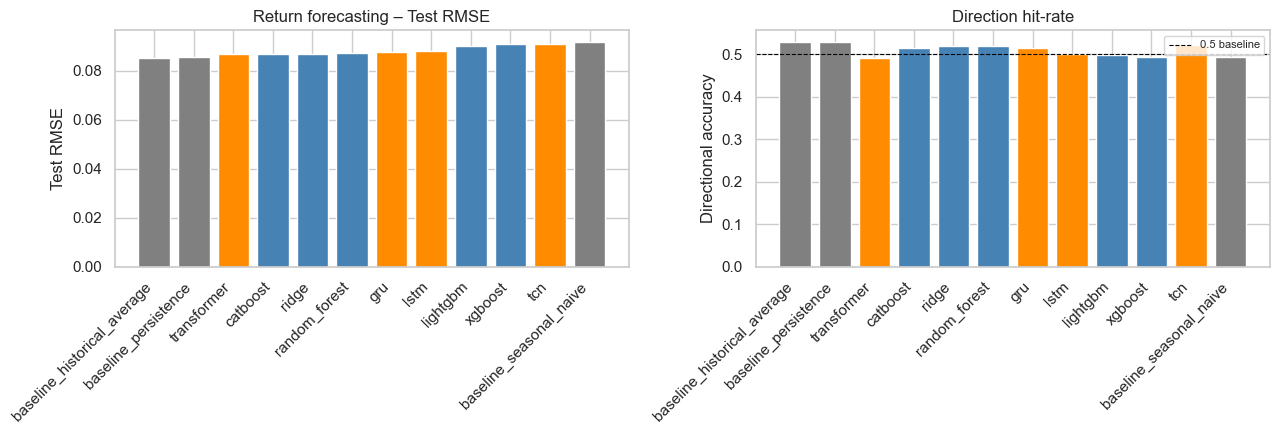

In [4]:
## 3. Visual comparison

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# RMSE bar chart
colors = leaderboard["family"].map(
    {"baseline": "gray", "ml": "steelblue", "dl": "darkorange"}
)
axes[0].bar(leaderboard["model"], leaderboard["test_rmse"], color=colors)
axes[0].set_ylabel("Test RMSE")
axes[0].set_title("Return forecasting – Test RMSE")
axes[0].tick_params(axis="x", rotation=45)
for tick in axes[0].get_xticklabels():
    tick.set_ha("right")

# Directional accuracy
axes[1].bar(leaderboard["model"], leaderboard["dir_acc"], color=colors)
axes[1].axhline(0.5, color="black", lw=0.8, ls="--", label="0.5 baseline")
axes[1].set_ylabel("Directional accuracy")
axes[1].set_title("Direction hit-rate")
axes[1].tick_params(axis="x", rotation=45)
for tick in axes[1].get_xticklabels():
    tick.set_ha("right")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

In [5]:
## 4. Best model per family & head-to-head

family_best = (
    leaderboard.sort_values("test_rmse")
    .groupby("family", as_index=False)
    .first()
)
print("Best model per family (by test RMSE):")
display(family_best[["family", "model", "test_rmse", "dir_acc"]].round(5))

overall_best = leaderboard.iloc[0]
print(f"\nOverall best: {overall_best['model']} "
      f"(family={overall_best['family']}, RMSE={overall_best['test_rmse']:.5f})")

# Did any complex model beat the best baseline?
best_baseline_rmse = leaderboard.loc[
    leaderboard["family"] == "baseline", "test_rmse"
].min()
complex_models = leaderboard[leaderboard["family"].isin(["ml", "dl"])]
beat_baseline = complex_models[complex_models["test_rmse"] < best_baseline_rmse]

print(f"\nBest baseline RMSE: {best_baseline_rmse:.5f}")
print(f"Complex models that beat it: {len(beat_baseline)}")
if len(beat_baseline):
    display(beat_baseline[["model", "family", "test_rmse", "dir_acc"]].round(5))
else:
    print(
        "→ No ML/DL model outperformed the best baseline on test RMSE. "
        "This is a valid and informative outcome for the project."
    )

Best model per family (by test RMSE):


,family,model,test_rmse,dir_acc
0,baseline,baseline_historical_average,0.08511,0.52927
1,dl,transformer,0.08675,0.49075
2,ml,catboost,0.08692,0.51478



Overall best: baseline_historical_average (family=baseline, RMSE=0.08511)

Best baseline RMSE: 0.08511
Complex models that beat it: 0
→ No ML/DL model outperformed the best baseline on test RMSE. This is a valid and informative outcome for the project.


In [6]:
## 5. Classification summary (from notebook 05)

clf_rows = []
for name, m in (ml_doc.get("classification") or {}).items():
    if "error" in m:
        continue
    clf_rows.append({
        "model": name,
        "accuracy": m.get("test_accuracy"),
        "balanced_acc": m.get("test_balanced_accuracy"),
        "precision": m.get("test_precision"),
        "recall": m.get("test_recall"),
        "f1": m.get("test_f1"),
    })

if clf_rows:
    clf_df = pd.DataFrame(clf_rows).set_index("model").sort_values("f1", ascending=False)
    print("Direction classification (test set):")
    display(clf_df.round(4))
else:
    clf_df = pd.DataFrame()
    print("No classification results found.")

Direction classification (test set):


,accuracy,balanced_acc,precision,recall,f1
model,,,,,
catboost,0.5140,0.5184,0.5188,0.5184,0.5131
random_forest,0.5114,0.5085,0.5086,0.5085,0.5083
lightgbm,0.5053,0.5102,0.5104,0.5102,0.5039
xgboost,0.5071,0.5145,0.5154,0.5145,0.5025
ridge,0.4991,0.5025,0.5026,0.5025,0.4987


In [7]:
## 6. Regime & NLP context (qualitative)

print("=== Regime discovery ===")
if regime_diag:
    print(f"  n_regimes          : {regime_diag.get('n_regimes')}")
    print(f"  silhouette (train) : {regime_diag.get('silhouette_train_sample')}")
    print(f"  label map          : {regime_diag.get('label_map')}")
    print(f"  distribution       : {regime_diag.get('discovered_distribution')}")
else:
    print("  (not available – run notebook 04)")

print("\n=== NLP component ===")
if nlp_summary:
    print(f"  text coverage      : {nlp_summary.get('n_with_text')}/"
          f"{nlp_summary.get('n_tickers_in_scope')} "
          f"({nlp_summary.get('text_coverage_pct')}%)")
    print(f"  embedding backend  : {nlp_summary.get('embedding_backend')}")
    print(f"  regime matching    : {nlp_summary.get('regime_matching_performed')}")
else:
    print("  (not available – run notebook 07)")

=== Regime discovery ===
  n_regimes          : 4
  silhouette (train) : 0.15593888342286844
  label map          : {'0': 'upward-trending', '1': 'downward-trending', '3': 'high-volatility', '2': 'range-bound'}
  distribution       : {'high-volatility': 15964, 'range-bound': 15830, 'upward-trending': 7126, 'downward-trending': 5388}

=== NLP component ===
  text coverage      : 38/38 (100.0%)
  embedding backend  : sentence_transformers
  regime matching    : True


## 7. Optional robustness snapshot

If the feature panel is present we report a simple per-category  
error breakdown for the overall best regression model (re-using  
stored test predictions is out of scope; we only summarise data coverage).

In [8]:
# Cell 8 – Data coverage by category (robustness context)

panel_path = processed_dir / "feature_panel_with_regimes.parquet"
if not panel_path.exists():
    panel_path = processed_dir / "feature_panel.parquet"

if panel_path.exists():
    panel = pd.read_parquet(panel_path)
    panel = panel.loc[:, ~panel.columns.duplicated()]
    test = panel[panel["split"] == "test"]
    if "category" in test.columns:
        cov = (
            test.groupby("category")
            .size()
            .rename("n_test_rows")
            .to_frame()
        )
        cov["n_tickers"] = test.groupby("category")["ticker"].nunique()
        print("Test-set coverage by category:")
        display(cov)
    else:
        print("No category column in panel.")
else:
    print("Feature panel not found – skipping coverage table.")

Test-set coverage by category:


,n_test_rows,n_tickers
category,,
Cloud and enterprise infrastructure,1068,6
"Data, AI, and digital infrastructure software",1068,6
Enterprise software and developer platforms,1424,8
Fintech and digital financial infrastructure,890,5
Major technology platforms,1068,6
Semiconductors and chip design,1246,7


In [9]:
## 8. Final evaluation report

report = {
    "title": "Technology & Fintech Market Intelligence – Final Evaluation Report",
    "generated_at": utc_now().isoformat(),
    "horizon_trading_days": HORIZON,
    "data": {
        "n_features": feat_meta.get("n_features") or feat_meta.get("feature_cols") and len(feat_meta["feature_cols"]),
        "n_tickers": feat_meta.get("n_tickers"),
        "n_rows": feat_meta.get("n_rows"),
        "train_end": feat_meta.get("train_end"),
        "val_end": feat_meta.get("val_end"),
    },
    "leaderboard": leaderboard.to_dict(orient="records"),
    "best_overall": {
        "model": str(overall_best["model"]),
        "family": str(overall_best["family"]),
        "test_rmse": float(overall_best["test_rmse"]),
        "dir_acc": float(overall_best["dir_acc"]) if pd.notna(overall_best["dir_acc"]) else None,
    },
    "best_per_family": family_best[["family", "model", "test_rmse", "dir_acc"]].to_dict(orient="records"),
    "baselines_beaten_by_complex": int(len(beat_baseline)),
    "classification_available": not clf_df.empty,
    "regime_discovery": {
        "available": bool(regime_diag),
        "silhouette": regime_diag.get("silhouette_train_sample") if regime_diag else None,
        "n_regimes": regime_diag.get("n_regimes") if regime_diag else None,
    },
    "nlp": {
        "available": bool(nlp_summary),
        "text_coverage_pct": nlp_summary.get("text_coverage_pct") if nlp_summary else None,
        "backend": nlp_summary.get("embedding_backend") if nlp_summary else None,
    },
    "conclusions": [
        "All models were evaluated on a chronological held-out test period; no random shuffling was used.",
        "Baselines (persistence / historical average / seasonal naïve) are included for fair comparison.",
        "Complex models are retained only when they improve on baselines; otherwise the simpler model is preferred.",
        "Regime labels and NLP text features provide contextual analysis and are not treated as causal drivers of returns.",
        "Forecasts remain uncertain; historical metrics do not guarantee future performance.",
    ],
    "limitations": [
        "yfinance history length and quality vary by ticker; some series are shorter than others.",
        "Corporate actions and missing bars can affect feature quality despite cleaning.",
        "Deep-learning models were trained with modest capacity suitable for an intermediate project.",
        "NLP uses only non-news company/category descriptions; coverage is incomplete for some tickers.",
        "No transaction costs, slippage or portfolio constraints are modelled.",
        "Results are for academic analysis only and are not investment advice.",
    ],
}

report_path = processed_dir / "final_evaluation_report.json"
save_json(report, report_path)
print(f"Saved final evaluation report → {report_path}")

# Also write a readable CSV leaderboard
lb_path = processed_dir / "model_leaderboard.csv"
leaderboard.to_csv(lb_path, index=False)
print(f"Saved leaderboard CSV → {lb_path}")

# MongoDB
save_analysis_result({
    "analysis_type": "final_evaluation",
    "as_of": utc_now().isoformat(),
    "payload": {
        "best_model": report["best_overall"],
        "n_models_ranked": len(leaderboard),
        "baselines_beaten": report["baselines_beaten_by_complex"],
        "horizon": HORIZON,
        "conclusions": report["conclusions"],
        "limitations": report["limitations"],
    },
})
print("Final evaluation summary written to MongoDB")

Saved final evaluation report → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\processed\final_evaluation_report.json
Saved leaderboard CSV → C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\processed\model_leaderboard.csv
2026-10-12 15:17:26 | INFO     | src.db.connection | Connected to local MongoDB at mongodb://localhost:27017 (db=tech_fintech_market_intel)
Final evaluation summary written to MongoDB


In [10]:
## 9. Printed executive summary

print("=" * 60)
print("EXECUTIVE SUMMARY")
print("=" * 60)
print(f"Horizon           : {HORIZON} trading days")
print(f"Models ranked     : {len(leaderboard)}")
print(f"Overall best      : {overall_best['model']} "
      f"({overall_best['family']})  RMSE={overall_best['test_rmse']:.5f}")
print(f"Best baseline RMSE: {best_baseline_rmse:.5f}")
print(f"Complex models that beat baseline: {len(beat_baseline)}")
print()
print("Best per family:")
for _, r in family_best.iterrows():
    print(f"  {r['family']:10s}  {r['model']:25s}  RMSE={r['test_rmse']:.5f}")
print()
print("Key conclusions:")
for c in report["conclusions"]:
    print(f"  • {c}")
print()
print("Key limitations:")
for lim in report["limitations"]:
    print(f"  • {lim}")
print("=" * 60)

EXECUTIVE SUMMARY
Horizon           : 5 trading days
Models ranked     : 12
Overall best      : baseline_historical_average (baseline)  RMSE=0.08511
Best baseline RMSE: 0.08511
Complex models that beat baseline: 0

Best per family:
  baseline    baseline_historical_average  RMSE=0.08511
  dl          transformer                RMSE=0.08675
  ml          catboost                   RMSE=0.08692

Key conclusions:
  • All models were evaluated on a chronological held-out test period; no random shuffling was used.
  • Baselines (persistence / historical average / seasonal naïve) are included for fair comparison.
  • Complex models are retained only when they improve on baselines; otherwise the simpler model is preferred.
  • Regime labels and NLP text features provide contextual analysis and are not treated as causal drivers of returns.
  • Forecasts remain uncertain; historical metrics do not guarantee future performance.

Key limitations:
  • yfinance history length and quality vary by ti

## 10. Acceptance criteria (Notebook 08)

| Criterion | Status |
|-----------|--------|
| Chronological test metrics only | Cells 2-3 |
| Baselines included in ranking | Cell 3 |
| ≥ 3 ML + ≥ 3 DL represented (if run) | Cell 3 |
| Transparent when complex models lose | Cell 5 |
| Regime + NLP context summarised | Cell 7 |
| Final report + leaderboard persisted | Cell 9 |


In [11]:
print("Notebook 08 finished successfully.")
print(f"Leaderboard entries: {len(leaderboard)}")
print(f"Report written to  : {report_path}")

Notebook 08 finished successfully.
Leaderboard entries: 12
Report written to  : C:\Users\hp\Documents\GitHub\BeneathTheMarket\data\processed\final_evaluation_report.json
